<a href="https://colab.research.google.com/github/freyebeans/ASU-assignments/blob/main/MAT422/HW2.4/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 Section 2.4 MLE and Linear Regression
Michael Bishop

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(514)

## 2.4.1 MLE for Random Samples
By finding the maximum likelihood estimate, a point in parameter space that maximizes a likelihood function, we get a good estimate of the parameters of a probabilty distribution. This approach to estimating a probabilty distribution is called maximum likelihood estimation.

MLE mu-hat = 1.8761151481806368
MLE sigma-hat = 1.5093127469983754


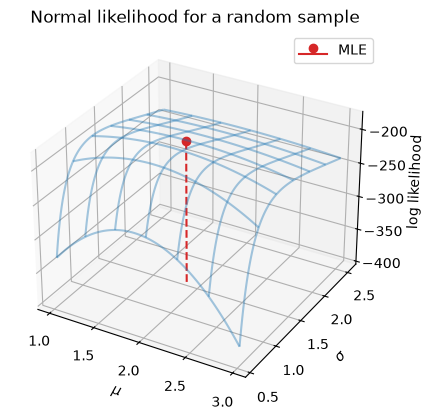

In [2]:
def apply(f, a):
    o = np.copy(a)
    for i, x in np.ndenumerate(a):
        o[i] = f(x)
    return o

n = 60
true_mean = 2
true_stdev = 1.5
sample = rng.normal(true_mean, true_stdev, n)
mu_hat = sample.mean()
sigma_hat = np.sqrt(((sample - sample.mean())**2).sum()/n)

grid_m, grid_s = np.meshgrid(np.linspace(1.01, 2.99, 300),np.linspace(0.56, 2.54, 300))
log_likelihood = -n*np.log(np.pi*2*grid_s*grid_s)-apply(lambda x: ((sample-x)**2).sum(),grid_m)/(2*grid_s*grid_s)

log_likelihood_max = -n*np.log(np.pi*2*sigma_hat*sigma_hat)-((sample-mu_hat)**2).sum()/(2*sigma_hat*sigma_hat)

print("MLE mu-hat =",mu_hat)
print("MLE sigma-hat =",sigma_hat)

plot = plt.figure().add_subplot(projection='3d')
plot.plot_wireframe(grid_m,grid_s,log_likelihood, rstride=50, cstride=50,alpha=0.4)
plot.stem([mu_hat],[sigma_hat],[log_likelihood_max],linefmt="C3--",markerfmt="C3o",bottom=-400,label="MLE")
plt.xlabel("$\\mu$")
plt.ylabel("$\\sigma$")
plot.set_zlabel("log likelihood")
plt.title("Normal likelihood for a random sample")
plt.legend()
plt.show()

As you can see the MLE's $\hat{\mu}$ and $\hat{\sigma}$ are close to the true values for $\mu$ and $\sigma$ and that those values of $\hat{\mu}$ and $\hat{\sigma}$ maximize the likelihood function.
## 2.4.2 Linear Regression
Linear regression revolves around finding a line that closely fits some data $x$ and $y$. While linear regression is a kind of least squares problem, it can also be formulated in terms of maximum likelihood estimation.

Estimated intercept and slope = [25.5369 -3.4904]
Residual sum of squares = 87.8792464483956


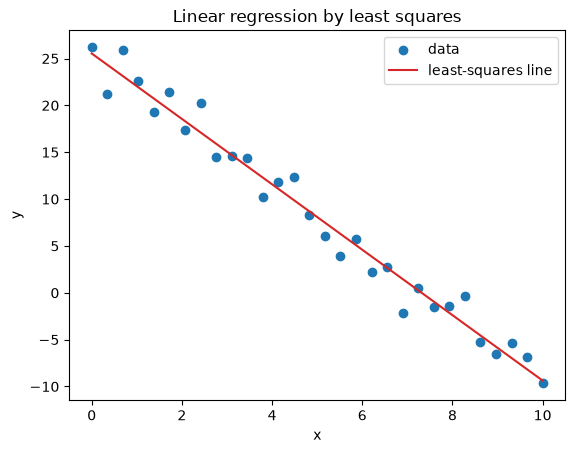

In [3]:
x = np.linspace(0, 10, 30)
y = 25 - 3.5 * x + rng.normal(0, 1.5, size=x.size)
X = np.column_stack([np.ones_like(x), x])
beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y
y_hat = X @ beta_hat
residuals = y - y_hat

print("Estimated intercept and slope =", beta_hat)
print("Residual sum of squares =", np.sum(residuals ** 2))

plt.scatter(x, y, label="data")
plt.plot(x, y_hat, color="tab:red", label="least-squares line")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear regression by least squares")
plt.legend()
plt.show()

As you can see, the line above closely fits the data. The data was created by deviating slightly from y = 25 - 3.5x and the estimated values give the line y = 25.5369 - 3.4904x which is very close to the line used to create the data.
## Reflection and Rubric Checklist
- I explained each concpet before and after the code.
- I verifed important claims numerically or visually.
- I changed and extended at least one example so that the notebook reflects my own work.
- I ran the notebook in its entirety without error.
- I saved the notebook from Google Colab directly to GitHub as per course instructions.